# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

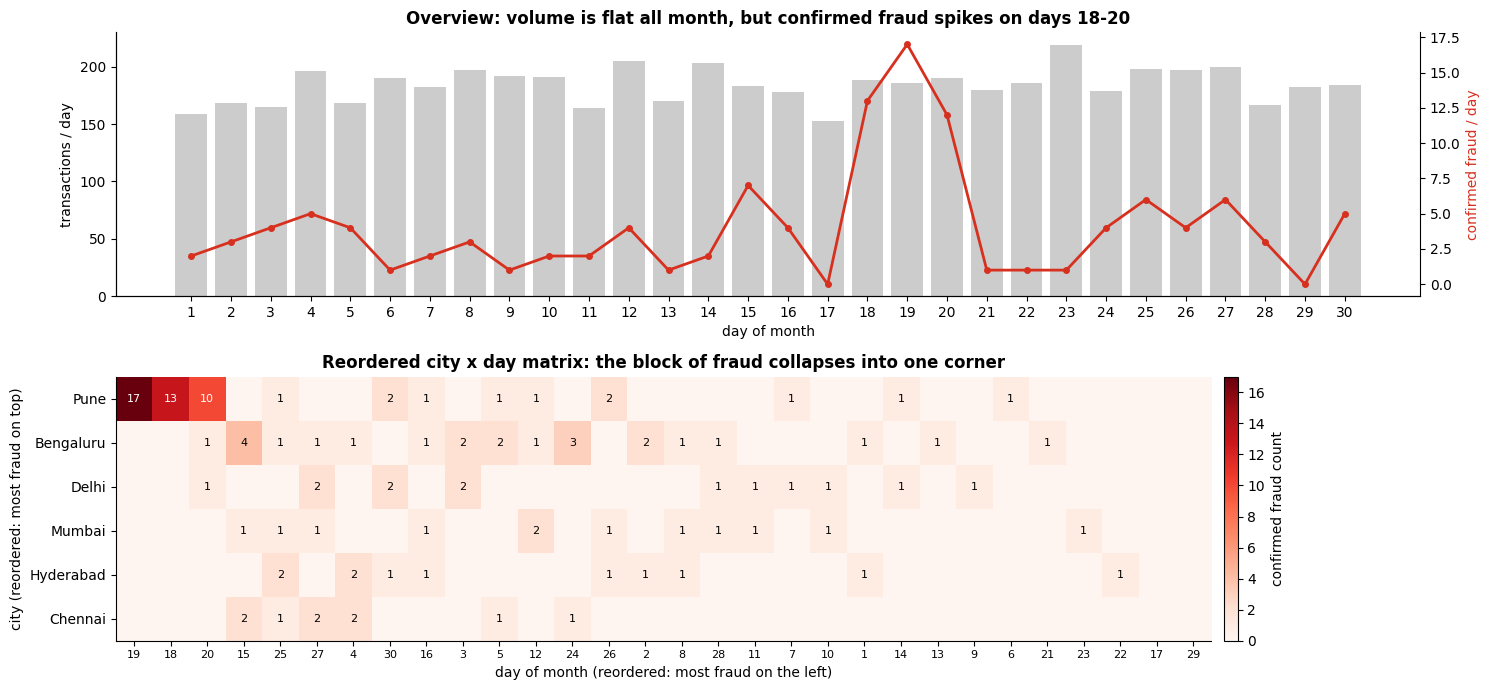

Top city-day cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2

All other 61 non-empty cells hold at most 4 fraud each.
Pune days 18-20: 40 of 120 confirmed fraud (33%) in 3 of 180 city-days
Transactions per day: min 153, max 219 -> volume itself shows no anomaly


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1: daily volume with daily confirmed fraud on a second axis
daily = tx.groupby("day").agg(n=("txn_id", "size"), fraud=("is_fraud", "sum"))
axes[0].bar(daily.index, daily.n, color="#cccccc", label="transactions")
axes[0].set_xlabel("day of month"); axes[0].set_ylabel("transactions / day")
ax2 = axes[0].twinx()
ax2.plot(daily.index, daily.fraud, "-o", color="#d7301f", ms=4, lw=2, label="confirmed fraud")
ax2.set_ylabel("confirmed fraud / day", color="#d7301f"); ax2.spines["right"].set_visible(True)
axes[0].set_xticks(daily.index)
axes[0].set_title("Overview: volume is flat all month, but confirmed fraud spikes on days 18-20",
                  fontweight="bold")

# TODO 2: city x day fraud-count matrix, rows and columns reordered by their totals
heat = pd.crosstab(tx.city, tx.day, values=tx.is_fraud, aggfunc="sum").fillna(0).astype(int)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, cmap="Reds", aspect="auto")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns, fontsize=8)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set_xlabel("day of month (reordered: most fraud on the left)")
axes[1].set_ylabel("city (reordered: most fraud on top)")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if v:
            axes[1].text(j, i, v, ha="center", va="center", fontsize=8,
                         color="white" if v > heat.values.max() / 2 else "black")
fig.colorbar(im, ax=axes[1], label="confirmed fraud count", pad=0.01)
axes[1].set_title("Reordered city x day matrix: the block of fraud collapses into one corner", fontweight="bold")
plt.tight_layout(); plt.show()

# TODO 3: the (city, day) cells with the most fraud
cells = heat.stack().sort_values(ascending=False)
print("Top city-day cells by confirmed fraud:")
print(cells.head(6).to_string())
print(f"\nAll other {(cells > 0).sum() - 3} non-empty cells hold at most {cells.iloc[3:].max()} fraud each.")
print(f"Pune days 18-20: {cells.loc['Pune'][[18, 19, 20]].sum()} of {tx.is_fraud.sum()} confirmed fraud "
      f"({cells.loc['Pune'][[18, 19, 20]].sum() / tx.is_fraud.sum():.0%}) in 3 of {heat.size} city-days")
print(f"Transactions per day: min {daily.n.min()}, max {daily.n.max()} -> volume itself shows no anomaly")


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview showed that the problem is **concentrated in place and time**: **40 of the month's 120 confirmed fraud
cases (33%) happened in Pune on days 18–20** — 3 of the 180 city-days — with 13, 17 and 10 cases on those days against
at most 4 in any other city-day. Daily *volume* stayed flat (153–219 transactions/day), so nothing in the activity level
would have raised the alarm.

An alert list sorted by detector score would show none of that. It lists individual transactions; the Pune cases would be
near the top (their median score is 0.95) but **interleaved with high-scoring cases from every other city and day**, and a
list has no axis on which a city-day cluster could appear. The pattern only exists once transactions are aggregated and
arranged by city and day.

The concept is the **reorderable matrix** (Slide 39), combined with **overview first**: sorting the rows and columns
of the city × day matrix by their totals pulls the dense block into one corner, where it is impossible to miss.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

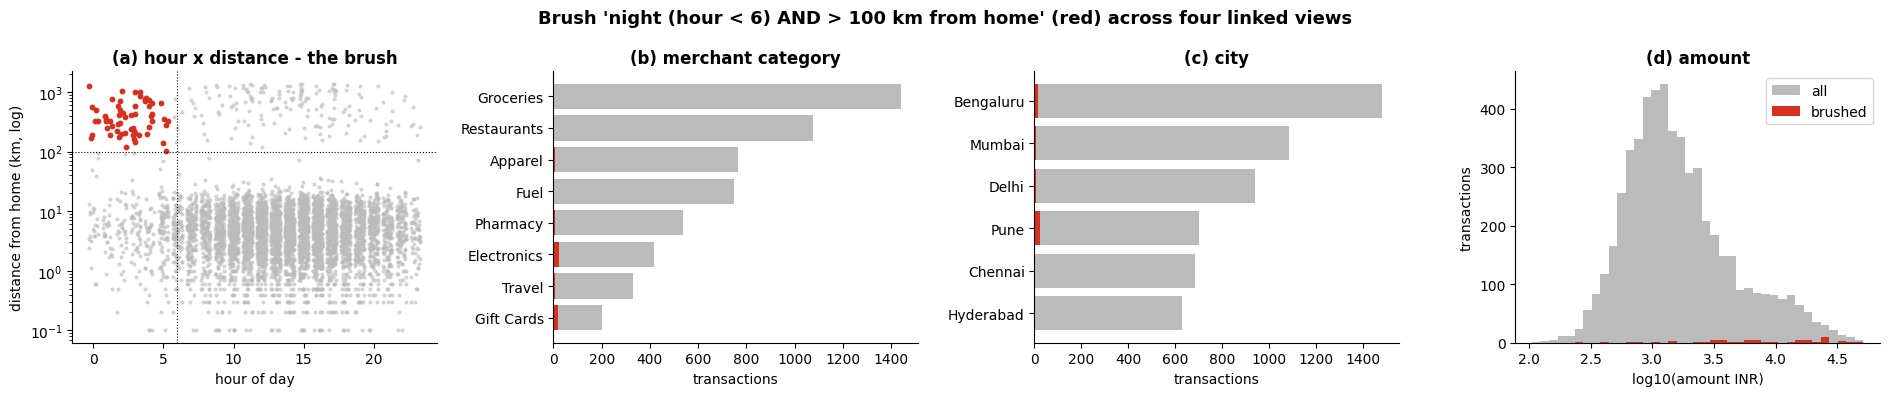

brushed: 61 transactions (1.1% of all)
fraud rate inside the brush: 86.9%  vs overall 2.2%  (40x)
share of ALL fraud the brush captures: 44.2% (53 of 120)

The 67 fraud cases OUTSIDE the brush:
  city: {'Pune': 27, 'Bengaluru': 10, 'Mumbai': 9}
  night: 15% | median distance 144 km | top categories {'Electronics': 26, 'Gift Cards': 24, 'Travel': 10}


In [3]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

RED, GREY = "#d7301f", "#bbbbbb"
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2: four coordinated views, brushed items in red over all items in grey
dist = tx.distance_from_home_km.clip(lower=0.1)
jit = np.random.uniform(-0.35, 0.35, len(tx))
axes[0].scatter(tx.hour + jit, dist, s=4, c=GREY, alpha=0.5)
axes[0].scatter((tx.hour + jit)[brush], dist[brush], s=10, c=RED)
axes[0].set_yscale("log"); axes[0].set_xlabel("hour of day"); axes[0].set_ylabel("distance from home (km, log)")
axes[0].axvline(6, color="k", ls=":", lw=0.8); axes[0].axhline(100, color="k", ls=":", lw=0.8)
axes[0].set_title("(a) hour x distance - the brush", fontweight="bold")

for ax, col, title in [(axes[1], "merchant_category", "(b) merchant category"), (axes[2], "city", "(c) city")]:
    allc = tx[col].value_counts()
    sel = tx.loc[brush, col].value_counts().reindex(allc.index, fill_value=0)
    ax.barh(allc.index, allc.values, color=GREY)
    ax.barh(sel.index, sel.values, color=RED)
    ax.invert_yaxis(); ax.set_xlabel("transactions"); ax.set_title(title, fontweight="bold")

bins = np.linspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 40)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color=GREY, label="all")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=bins, color=RED, label="brushed")
axes[3].set_xlabel("log10(amount INR)"); axes[3].set_ylabel("transactions"); axes[3].legend()
axes[3].set_title("(d) amount", fontweight="bold")
fig.suptitle("Brush 'night (hour < 6) AND > 100 km from home' (red) across four linked views",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

# TODO 3
n_b = int(brush.sum())
rate_in, rate_all = tx.is_fraud[brush].mean(), tx.is_fraud.mean()
captured = tx.is_fraud[brush].sum() / tx.is_fraud.sum()
print(f"brushed: {n_b} transactions ({n_b/len(tx):.1%} of all)")
print(f"fraud rate inside the brush: {rate_in:.1%}  vs overall {rate_all:.1%}  ({rate_in/rate_all:.0f}x)")
print(f"share of ALL fraud the brush captures: {captured:.1%} ({tx.is_fraud[brush].sum()} of {tx.is_fraud.sum()})")
missed = tx[(tx.is_fraud == 1) & ~brush]
print(f"\nThe {len(missed)} fraud cases OUTSIDE the brush:")
print(f"  city: {missed.city.value_counts().head(3).to_dict()}")
print(f"  night: {missed.night.mean():.0%} | median distance {missed.distance_from_home_km.median():.0f} km | "
      f"top categories {missed.merchant_category.value_counts().head(3).to_dict()}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The brush is extremely *precise*: **86.9%** of its 61 transactions are fraud — **40x** the 2.2% baseline. But it
**captures only 44.2% of all fraud (53 of 120)**. A rule built on "night-time, far-from-home" would miss **67 confirmed
fraud cases**, more than half.

So the investigators' rule of thumb is a good *alarm* but a poor *net*: it is right when it fires, yet most fraud does not
look like that. The 67 cases outside it are mostly **daytime** (only 15% at night), still a long way from home (median
**144 km**), and concentrated in **Electronics (26)** and **Gift Cards (24)**.

The **city view (c)** and the **merchant-category view (b)** point to the rest: Pune holds **27** of the 67 missed cases,
and the missed fraud sits in the same high-resale categories (Gift Cards, Electronics) as the brushed fraud. That suggests
the next brush to try — Pune, or Gift Cards/Electronics far from home at *any* hour — which is exactly the iterative
use of linked views that brushing is for.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: best of 5 runs of the filter
times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (per_item_us / 1e6)

# TODO 3
t_50m = 50_000_000 * per_item_us / 1e6
skip_pct = max(0.0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")
print(f"(runs: {', '.join(f'{t*1000:.1f}' for t in times)} ms -- the numbers are machine-dependent; "
      f"the 0.1 s budget is not)")
print(f"\nslide's worked example used 2 us/item -> max 50,000 items; vectorised pandas here is "
      f"{2/per_item_us:,.0f}x faster per item, which is why it reaches {max_rows/1e6:.1f}M rows")


1,004,640 rows in 19.1 ms -> 0.0190 us/row -> max 5,266,623 rows in 0.1 s
50M rows -> 0.95 s; must skip 89.5% of rows to stay under 0.1 s
(runs: 25.7, 21.2, 30.0, 19.1, 23.3 ms -- the numbers are machine-dependent; the 0.1 s budget is not)

slide's worked example used 2 us/item -> max 50,000 items; vectorised pandas here is 105x faster per item, which is why it reaches 5.3M rows


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

On this machine the filter ran at about **0.019 µs per row**, so the 0.1 s budget covers about **5.3 million rows**; 50
million rows would take about **0.95 s**, and **~89.5%** of the rows would need to be skipped to stay inside the budget.
(The exact timing varies between runs and machines, but the conclusion does not: a raw scan of 50M rows is several
times over budget.)

A **reduce** technique that fixes this without an index is **aggregation** — pre-compute a binned summary (e.g. counts and
fraud counts per score-bin × amount-bin × day × city). The slider then queries a few thousand pre-aggregated cells
instead of 50 million rows, so its cost no longer grows with the data. What the analyst loses is the **individual
transaction**: the view can say "37 transactions in this bin, 12 fraud" but cannot show *which* ones, hover their details
or pick up an outlier inside a bin; the bin edges also fix the resolution at which the slider can move. (Sampling is the
other reduce option, but with a 2.2% fraud rate a small sample can easily drop a rare pattern such as a 40-case ring
altogether.)

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,f1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
1,0.10,1167,111,1056,9,0.095,0.925,0.172
2,0.15,786,110,676,10,0.140,0.917,0.243
3,0.20,596,106,490,14,0.178,0.883,0.296
4,0.25,471,105,366,15,0.223,0.875,0.355
5,0.30,401,104,297,16,0.259,0.867,0.399
6,0.35,355,104,251,16,0.293,0.867,0.438
7,0.40,319,104,215,16,0.326,0.867,0.474
8,0.45,283,104,179,16,0.367,0.867,0.516
9,0.50,260,101,159,19,0.388,0.842,0.532


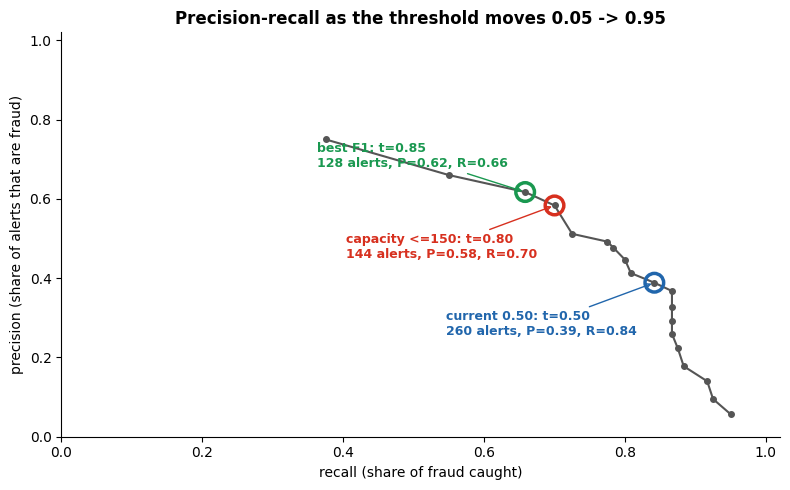

current t=0.50: 260 alerts/month, precision 38.8%, recall 84.2% -> 110 over capacity
best F1       : t=0.85, 128 alerts, F1 0.637
RECOMMENDATION: raise the threshold to 0.80 -> 144 alerts/month (within the 150 capacity), precision 58.3%, recall 70.0%; 36 of 120 fraud cases would go unreviewed.


In [5]:
rows = []
# TODO 1
for th in np.round(np.arange(0.05, 0.951, 0.05), 2):
    flag = tx.detector_score >= th
    TP = int((flag & (tx.is_fraud == 1)).sum()); FP = int((flag & (tx.is_fraud == 0)).sum())
    FN = int((~flag & (tx.is_fraud == 1)).sum())
    prec = TP / (TP + FP) if TP + FP else np.nan
    rec = TP / (TP + FN)
    f1 = 2 * prec * rec / (prec + rec) if TP else 0.0
    rows.append(dict(threshold=th, alerts=int(flag.sum()), TP=TP, FP=FP, FN=FN,
                     precision=prec, recall=rec, f1=f1))

pr = pd.DataFrame(rows).astype({"alerts": object, "TP": object, "FP": object, "FN": object})
display(pr.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "threshold": "{:.2f}"}))

# TODO 2
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.f1.idxmax()]
current = pr.loc[(pr.threshold - 0.5).abs().idxmin()]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", color="#555555", ms=4, lw=1.5)
for r, name, col in [(current, "current 0.50", "#2166ac"), (capacity_choice, "capacity <=150", "#d7301f"),
                     (best_f1, "best F1", "#1a9850")]:
    ax.scatter(r.recall, r.precision, s=180, facecolor="none", edgecolor=col, lw=2.5, zorder=5)
    ax.annotate(f"{name}: t={r.threshold:.2f}\n{r.alerts} alerts, P={r.precision:.2f}, R={r.recall:.2f}",
                (r.recall, r.precision), textcoords="offset points", xytext=(-150, -38 if name != "best F1" else 18),
                fontsize=9, color=col, fontweight="bold", arrowprops=dict(arrowstyle="->", color=col))
ax.set_xlabel("recall (share of fraud caught)"); ax.set_ylabel("precision (share of alerts that are fraud)")
ax.set_title("Precision-recall as the threshold moves 0.05 -> 0.95", fontweight="bold")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

# TODO 4
print(f"current t=0.50: {current.alerts} alerts/month, precision {current.precision:.1%}, recall {current.recall:.1%} "
      f"-> {current.alerts - 150} over capacity")
print(f"best F1       : t={best_f1.threshold:.2f}, {best_f1.alerts} alerts, F1 {best_f1.f1:.3f}")
print(f"RECOMMENDATION: raise the threshold to {capacity_choice.threshold:.2f} -> {capacity_choice.alerts} alerts/month "
      f"(within the 150 capacity), precision {capacity_choice.precision:.1%}, recall {capacity_choice.recall:.1%}; "
      f"{capacity_choice.FN} of {tx.is_fraud.sum()} fraud cases would go unreviewed.")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The two choices are close but not the same: **capacity-constrained t = 0.80** gives **144 alerts**, precision **58.3%**,
recall **70.0%**; **best-F1 t = 0.85** gives 128 alerts and F1 **0.637** — barely above 0.80's F1 of 0.636. Moving from
0.85 to 0.80 costs 16 more alerts and catches 5 more fraud cases.

**The Head of Fraud Ops should make that call, not the model.** F1 is a convenient summary, but it assumes a missed fraud
and a false alarm cost the same, which is almost never true: a missed fraud is lost money and a customer harmed; a false
alarm is a few minutes of an investigator's time. The model doesn't know the team can review **150** alerts a month, that
there was a concentrated attack in Pune this month, or how much an unreviewed case costs — the human does.

That is why visual analytics insists on a **human in the loop** (Slides 35–37): the system's job is to make the trade-off
**visible** — the precision–recall curve with the current, capacity and best-F1 points marked — so that the person
accountable for the decision can **steer** the parameter with full context, and can steer it again next month when
conditions change.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1: interactive triage scatter with details-on-demand tooltips
flagged = tx[tx.detector_score >= 0.3].copy()
fig1 = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    color_discrete_map={"confirmed fraud": "#d7301f", "legitimate": "#9e9e9e"},
    hover_data={"txn_id": True, "customer_id": True, "city": True, "merchant_category": True,
                "distance_from_home_km": ":.0f", "detector_score": ":.3f",
                "timestamp": False, "amount_inr": ":,.0f", "label": False},
    title=f"{len(flagged)} transactions with detector score >= 0.3 - hover a dot for its details, "
          f"drag to select a group",
)
fig1.update_traces(marker=dict(size=7, opacity=0.8))
fig1.update_layout(dragmode="select", height=480, legend_title_text="")
fig1.show()

# TODO 2: drill-down sunburst city -> merchant category, sized by count, coloured by fraud rate
sb = (tx.groupby(["city", "merchant_category"])
        .agg(n=("txn_id", "size"), fraud=("is_fraud", "sum")).reset_index())
sb["fraud_rate"] = sb.fraud / sb.n
fig2 = px.sunburst(sb, path=["city", "merchant_category"], values="n", color="fraud_rate",
                   color_continuous_scale="Reds", hover_data={"fraud": True},
                   title="Drill-down: click a city to open its merchant categories (colour = fraud rate)")
fig2.update_layout(height=560)
fig2.show()

print(f"{len(flagged)} flagged for triage; {flagged.is_fraud.sum()} of them are confirmed fraud "
      f"({flagged.is_fraud.sum()/tx.is_fraud.sum():.0%} of all fraud)")
print("Highest fraud-rate city x category cells:")
print(sb.sort_values("fraud_rate", ascending=False).head(5)
        .assign(fraud_rate=lambda d: (d.fraud_rate * 100).round(1)).to_string(index=False))


401 flagged for triage; 104 of them are confirmed fraud (87% of all fraud)
Highest fraud-rate city x category cells:
     city merchant_category  n  fraud  fraud_rate
     Pune        Gift Cards 37     21        56.8
     Pune       Electronics 72     18        25.0
Bengaluru        Gift Cards 48      9        18.8
  Chennai        Gift Cards 30      4        13.3
Hyderabad       Electronics 48      6        12.5


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

A tooltip shows **one case, only while the mouse is over it**. For the 401 transactions with score ≥ 0.3, getting an
overview through tooltips would mean 401 separate hovers, each wiping out the previous one — the investigator would have
to remember every city, category and score in their head to see a pattern. That is the limit the lecture puts on
**details-on-demand** (Slide 23): it answers "what is *this* point?", not "what are these points like *as a group*?".

The view that fixes it is an **aggregate overview**: the **reordered city × day heatmap** from Task 1 (which shows the
Pune days 18–20 block at a glance), and the **sunburst**, whose colour makes it obvious that **Pune Gift Cards (56.8%
fraud)** and **Pune Electronics (25.0%)** are the hottest segments before any individual case is opened. The right
workflow is the mantra in order — overview from the heatmap/sunburst, filter to the hot segment, *then* use tooltips on
the few dozen remaining cases.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

is_fraud          legitimate  fraud
row_0                              
outside window          5333     80
Pune, days 18-20          67     40

fraud rate inside 37.4% (40/107) vs outside 1.48% -> 25x;  chi2 = 619.3, p = 1.06e-136

Counter-example search:
                                    n  fraud    rate
Pune, days 18-20 (hypothesis)   107.0   40.0  37.38%
Pune, other days                593.0   11.0   1.85%
other cities, days 18-20        457.0    2.0   0.44%
everything else                4363.0   67.0   1.54%

Inside the window the fraud is: {'Gift Cards': 16, 'Electronics': 15}, 40 distinct customers, night share 65%, median distance 283 km, median score 0.95


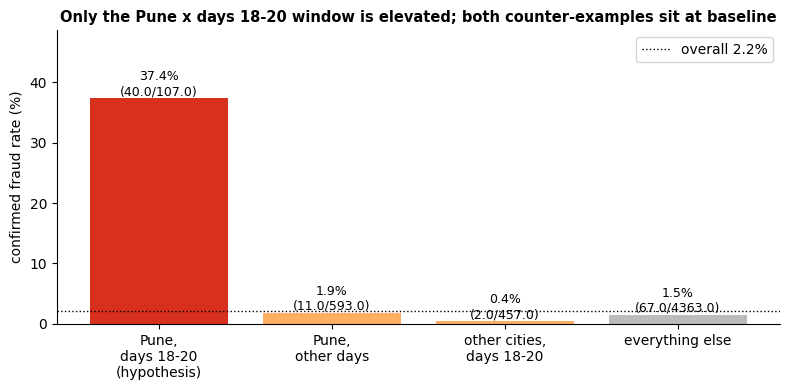


VERDICT: hypothesis SUPPORTED - fraud is 25x elevated in Pune on days 18-20 (p = 1.1e-136); neither Pune on other days (1.9%) nor other cities on those days (0.4%) is elevated, so it is a localised event rather than a city-wide or a nationwide pattern.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# H1: "a fraud ring operated in Pune on days 18-20" -> fraud is concentrated in that city-day window
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
ct = pd.crosstab(in_window, tx.is_fraud)
chi2, p_value, dof, _ = chi2_contingency(ct)
r_in, r_out = tx.is_fraud[in_window].mean(), tx.is_fraud[~in_window].mean()
print(ct.rename(index={False: "outside window", True: "Pune, days 18-20"},
                columns={0: "legitimate", 1: "fraud"}).to_string())
print(f"\nfraud rate inside {r_in:.1%} ({tx.is_fraud[in_window].sum()}/{in_window.sum()}) vs outside {r_out:.2%} "
      f"-> {r_in/r_out:.0f}x;  chi2 = {chi2:.1f}, p = {p_value:.2e}")

# TODO 3: counter-example searches
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = ~(in_window | same_city_other_days | other_cities_same_days)
groups = {"Pune, days 18-20 (hypothesis)": in_window,
          "Pune, other days": same_city_other_days,
          "other cities, days 18-20": other_cities_same_days,
          "everything else": rest}
stats = pd.DataFrame({k: {"n": int(m.sum()), "fraud": int(tx.is_fraud[m].sum()), "rate": tx.is_fraud[m].mean()}
                      for k, m in groups.items()}).T
print("\nCounter-example search:")
print(stats.assign(rate=lambda d: (d.rate.astype(float) * 100).round(2).astype(str) + "%").to_string())

# what else is different inside the window?
w = tx[in_window & (tx.is_fraud == 1)]
print(f"\nInside the window the fraud is: {w.merchant_category.value_counts().head(2).to_dict()}, "
      f"{w.customer_id.nunique()} distinct customers, night share {w.night.mean():.0%}, "
      f"median distance {w.distance_from_home_km.median():.0f} km, median score {w.detector_score.median():.2f}")

# TODO 4: visual confirmation
fig, ax = plt.subplots(figsize=(8, 4))
cols = ["#d7301f", "#fdae61", "#fdae61", "#bbbbbb"]
bars = ax.bar([k.replace(", ", ",\n").replace(" (", "\n(") for k in stats.index],
              stats.rate.astype(float) * 100, color=cols)
for b, (_, r) in zip(bars, stats.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{float(r.rate):.1%}\n({r.fraud}/{r.n})",
            ha="center", va="bottom", fontsize=9)
ax.axhline(tx.is_fraud.mean() * 100, color="k", ls=":", lw=1, label=f"overall {tx.is_fraud.mean():.1%}")
ax.set_ylabel("confirmed fraud rate (%)"); ax.legend()
ax.set_ylim(0, float(stats.rate.max()) * 100 * 1.3)
ax.set_title("Only the Pune x days 18-20 window is elevated; both counter-examples sit at baseline",
             fontweight="bold", fontsize=10.5)
plt.tight_layout(); plt.show()

# TODO 5: verdict
base = float(stats.loc["everything else", "rate"])
ok_city = float(stats.loc["Pune, other days", "rate"]) < 2 * base
ok_days = float(stats.loc["other cities, days 18-20", "rate"]) < 2 * base
verdict = "SUPPORTED" if (p_value < 0.001 and ok_city and ok_days) else "NOT SUPPORTED"
print(f"\nVERDICT: hypothesis {verdict} - fraud is {r_in/r_out:.0f}x elevated in Pune on days 18-20 (p = {p_value:.1e}); "
      f"neither Pune on other days ({float(stats.loc['Pune, other days', 'rate']):.1%}) nor other cities on those days "
      f"({float(stats.loc['other cities, days 18-20', 'rate']):.1%}) is elevated, so it is a localised "
      f"event rather than a city-wide or a nationwide pattern.")


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

**Either counter-example could have killed the specific hypothesis, each in favour of a different explanation:**

- **(b) Other cities on the same days.** If those had also been elevated, the spike would be a **time-wide event**, not
  a Pune ring — a nationwide card-data breach, a BIN attack across the network, or something mundane like a change in the
  detector or in how investigators labelled cases on those days. In fact other cities on days 18–20 were at **0.44%**,
  *below* the 1.54% baseline.
- **(a) Pune on other days.** If Pune had been high all month, the story would be **a chronic city-level risk** (a
  compromised merchant or terminal operating for weeks), not a three-day event. In fact Pune outside the window was
  **1.85%** — close to baseline.

Inside the window the rate is **37.4%** (40 of 107) versus **1.48%** elsewhere, **25x** higher, with χ² = 619 and
p ≈ 1e-136. So the data supports a **concentrated Pune, days 18–20 event**.

One honest limit: the data supports "concentrated event" more strongly than "**ring**". The 40 fraudulent transactions
belong to **40 different customers** (one each), are mostly Gift Cards and Electronics, 65% at night and a median of 283 km
from home — consistent with a batch of stolen card details being cashed out in one place. Whether one coordinated group
did it is a question for the investigators, not something this table can prove.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

**Note to the Head of Fraud Ops — last month's review**

**What happened.** Last month had **120 confirmed fraud cases out of 5,520 transactions (2.2%)**, and a third of them —
**40 cases — came from a single burst in Pune on days 18–20**, where the fraud rate was 37.4% against 1.5% everywhere else
(25x, p ≈ 1e-136); outside that window the month looked normal, and neither Pune on other days nor other cities on those
days was elevated.

**Alert threshold: raise it from 0.50 to 0.80.** At 0.50 the detector produces **260 alerts** a month — 110 more than the
team can review — at only 38.8% precision. At **0.80** it produces **144 alerts** (inside the capacity of 150), with
**58.3% precision and 70.0% recall**; the best-F1 setting (0.85) is statistically tied but catches 5 fewer fraud cases.
The cost is real and should be accepted knowingly: **36 of 120 fraud cases would go unreviewed**. Because that trade-off
depends on capacity and on what a missed case costs, it is a decision for you, re-made each month with the
precision–recall chart — not one to hand to the model.

**First interactive view to build: the reordered city × day overview heatmap with linked brushing into the transaction
list.** It is the view that found this month's main finding (**overview first**), and brushing a hot cell to filter the
list gives investigators the zoom-and-filter step before details-on-demand. To keep the slider responsive on the full
50M-row history it needs to sit on **pre-aggregated** data, since a raw scan measured close to 1 s against the 0.1 s
budget.

**Feedback loop.** Close the workflow's **feedback-to-the-model** loop (Slide 51): every case an investigator confirms
or rejects should be logged and used to **retrain or recalibrate the detector**. The Pune burst alone adds 40 confirmed
examples of the high-resale, far-from-home pattern, and the 67 confirmed cases that the "night, far-from-home" rule
misses — mostly daytime Gift Card / Electronics fraud — are exactly the labelled examples the detector needs so that
next month fewer fraud cases fall below the threshold.